0 - Importing Libraries

In [166]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
    RobustScaler
)

from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

1 - Problem framing

1.1 Project OverView 

Project Title: Mobile Wallet Fraud Detection

Mobile money services have become an essential part of digital financial transactions, enabling users to transfer money and perform cash-outs conveniently. However, the increasing volume of digital transactions also creates opportunities for fraudulent activities, resulting in financial losses for customers and payment service providers.

This project aims to develop a machine learning-based fraud detection system capable of identifying potentially fraudulent mobile money transactions and supporting faster, more reliable fraud prevention decisions.

1.2 Problem Statement

The main problem addressed in this project is the difficulty of identifying fraudulent transactions among a large volume of legitimate mobile money transactions.

The dataset contains highly imbalanced transaction records, where fraudulent transactions represent only a small proportion of all transactions. Therefore, a model that simply predicts every transaction as legitimate may achieve high accuracy while failing to detect actual fraud.

The challenge is to develop a model that can effectively identify fraudulent transactions while minimizing unnecessary alerts on legitimate transactions.

1.3 Stakeholders

The primary stakeholders who benefit from this system are:

Mobile Wallet Providers: Reduce financial losses and improve transaction security.

Fraud Detection Teams: Identify suspicious transactions and prioritize investigations.

Customers: Reduce the risk of unauthorized transactions and financial losses.

1.4 Business Decision

The model will support the decision of whether a mobile money transaction should be:

- Approved: The transaction is considered legitimate.

- Flagged for Review: The transaction has a high probability of being fraudulent and requires further investigation.

The model will generate a fraud probability score for each transaction. A configurable decision threshold will determine whether the transaction is flagged for review.

The final decision threshold will consider the trade-off between missed fraudulent transactions and false alarms.

1.5 Target Variable

The target variable is: isFraud

Value | Meaning
0     | Legitimate transaction
1     | Fraudulent transaction

This is a binary classification problem because the model predicts one of two possible classes.

1.6 Business Evaluation Metric

The primary evaluation metric will be Precision-Recall AUC (PR-AUC).

PR-AUC is particularly appropriate for this project because fraudulent transactions are extremely rare compared with legitimate transactions.

The evaluation will also include:

Recall: Measures the proportion of actual fraudulent transactions successfully detected. High recall helps reduce missed fraud.

Precision: Measures the proportion of flagged transactions that are actually fraudulent. High precision reduces unnecessary investigations and customer inconvenience.

F1-Score: Provides a balance between precision and recall.

Confusion Matrix: Shows correctly and incorrectly classified fraudulent and legitimate transactions.

In addition, a cost-based evaluation will be used to study the financial impact of missed fraud and false alarms at different classification thresholds.

1.7 Project Objective

The objective is to build and evaluate a machine learning pipeline that can distinguish fraudulent mobile money transactions from legitimate ones, optimize fraud detection performance under severe class imbalance, and provide an interactive web application that allows users to evaluate individual transactions or upload transaction files.



2 - Data Understanding 

2.1 Dataset Source

In [167]:
df = pd.read_csv("PS_20174392719_1491204439457_log.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


2.2 - Understand the columns

In [168]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
df.dtypes
df.info()
df.describe()

Number of Rows: 6362620
Number of Columns: 11
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


2.3 Column Dictionary

In [169]:
column_dictionary = pd.DataFrame({
    "Column": df.columns,
    "Description": [
        "Time step representing an hour",
        "Type of transaction",
        "Transaction amount",
        "Originating account ID",
        "Origin account balance before transaction",
        "Origin account balance after transaction",
        "Destination account ID",
        "Destination balance before transaction",
        "Destination balance after transaction",
        "Actual fraud label (1 or 0)",
        "Existing rule-based fraud flag (Indicates transaction flagged by existing rule)"
    ]
})

display(column_dictionary)

,Column,Description
0,step,Time step representing an hour
1,type,Type of transaction
2,amount,Transaction amount
3,nameOrig,Originating account ID
4,oldbalanceOrg,Origin account balance before transaction
5,newbalanceOrig,Origin account balance after transaction
6,nameDest,Destination account ID
7,oldbalanceDest,Destination balance before transaction
8,newbalanceDest,Destination balance after transaction
9,isFraud,Actual fraud label (1 or 0)


2.4 Data Types

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


2.5 - Missing Values

In [171]:
missing_values = df.isnull().sum()

print(missing_values)


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


2.6 Check duplicates

In [172]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


2.7 - Analyze class distribution

In [174]:
class_counts = df["isFraud"].value_counts()

class_percentage = df["isFraud"].value_counts(normalize=True) * 100

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentage
})

display(class_distribution)

,Count,Percentage
isFraud,,
0,6354407,99.870918
1,8213,0.129082


Visualization of class distribution

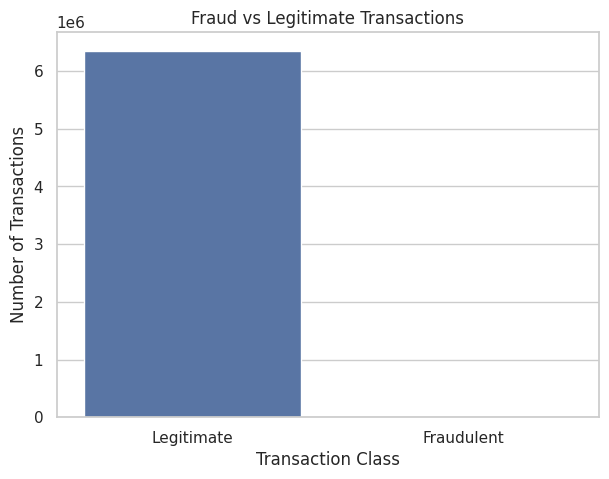

In [175]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="isFraud")

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()


Visualization using log scale 

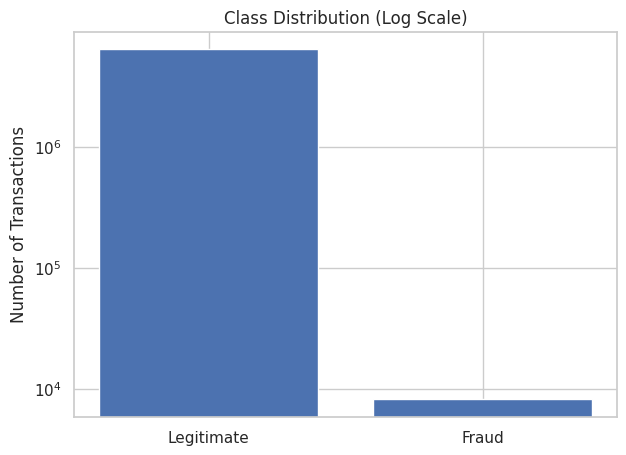

In [176]:
counts = df["isFraud"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Legitimate", "Fraud"],
    counts.values
)

plt.yscale("log")
plt.title("Class Distribution (Log Scale)")
plt.ylabel("Number of Transactions")

plt.show()

2.8 Class Imbalance Observation

In [177]:
fraud_percentage = class_percentage.loc[1]
legitimate_percentage = class_percentage.loc[0]

print(f"Legitimate Transactions: {legitimate_percentage:.4f}%")
print(f"Fraudulent Transactions: {fraud_percentage:.4f}%")
print(f"Class Imbalance Ratio: {class_counts.loc[0] / class_counts.loc[1]:.2f}:1")

Legitimate Transactions: 99.8709%
Fraudulent Transactions: 0.1291%
Class Imbalance Ratio: 773.70:1


3 - Exploratory Data Analysis (EDA)

3.1 Univariate Analysis

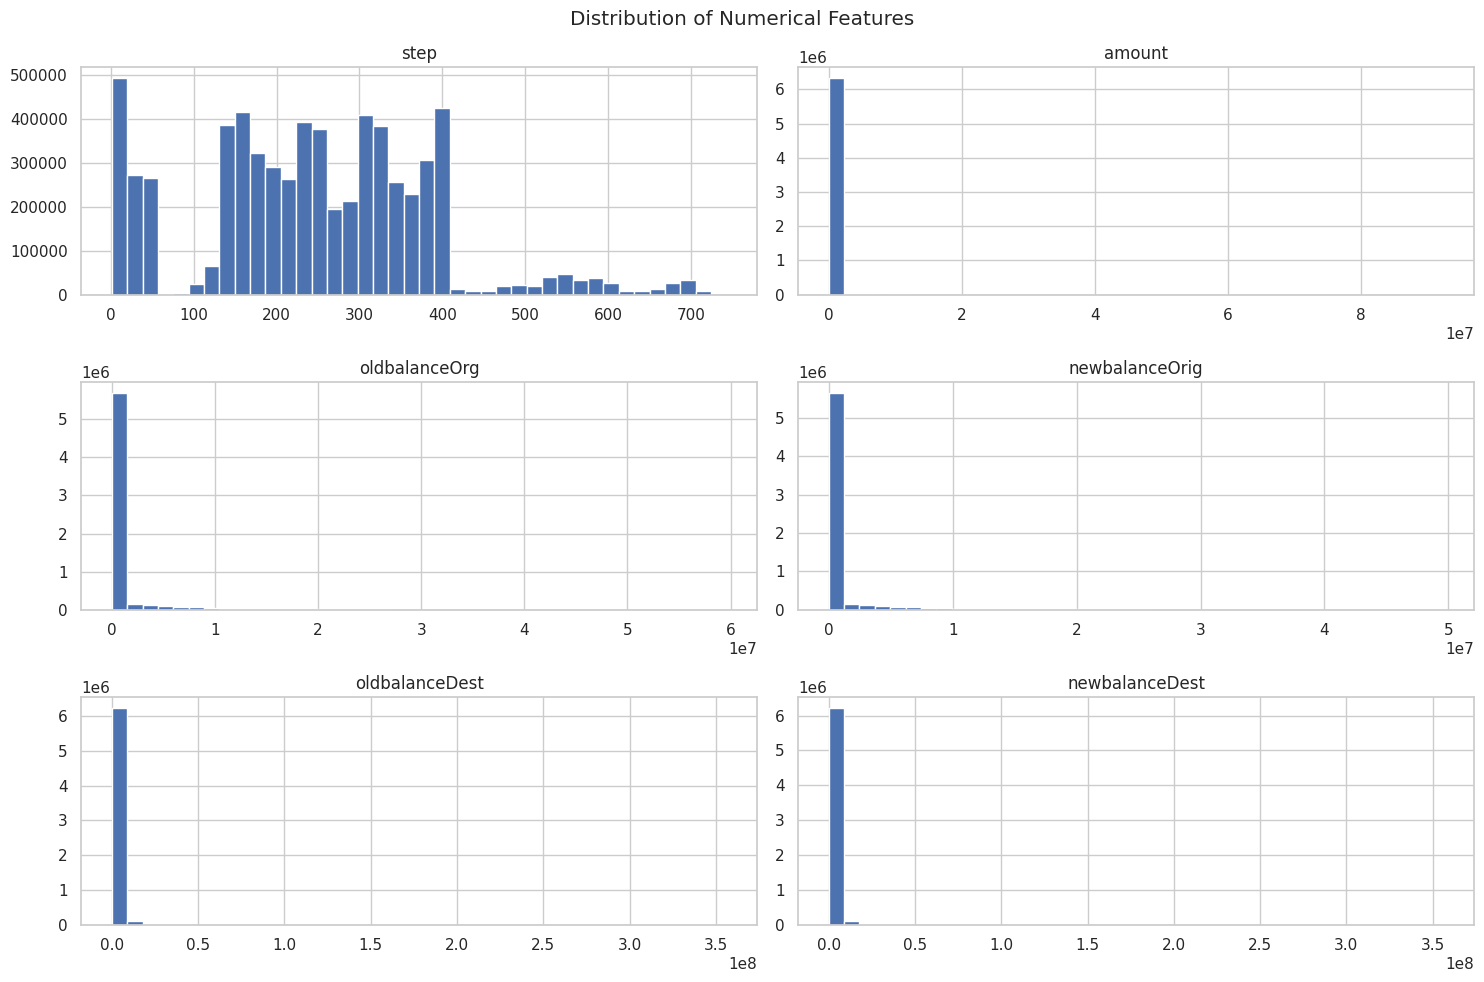

In [178]:
# Numerical features distribution:
numerical_features = [
    "step", "amount",
    "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest"
]

df[numerical_features].hist(
    figsize=(15, 10),
    bins=40
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

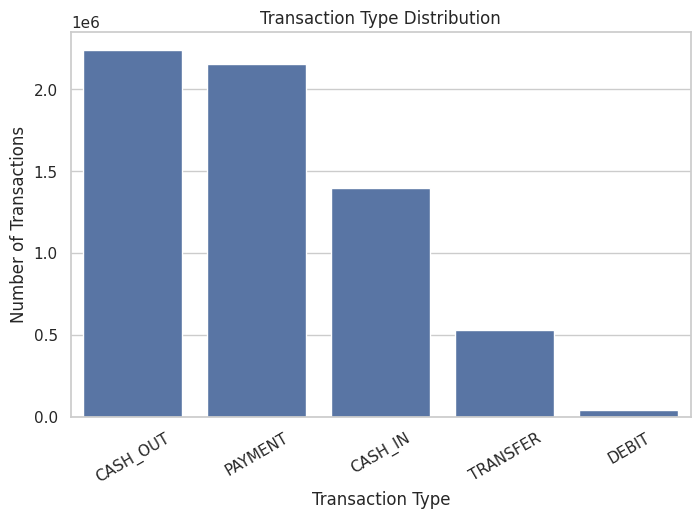

In [179]:
# Transaction types
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="type", order=df["type"].value_counts().index)

plt.title("Transaction Type Distribution")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

plt.show()

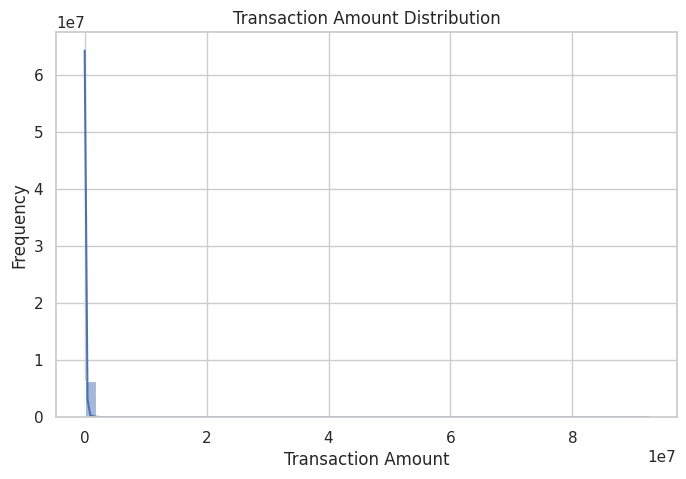

In [180]:
# Transaction amount distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["amount"], bins=50, kde=True)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

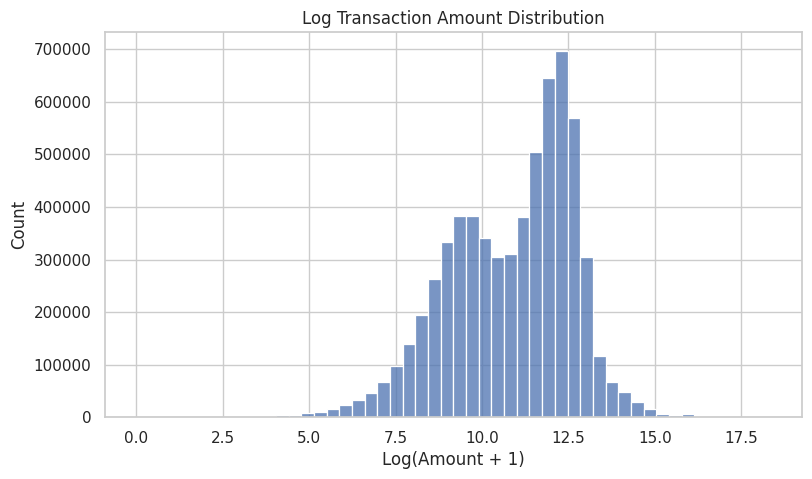

In [181]:
# Transaction amounts by logarithmic transformation
plt.figure(figsize=(9, 5))

sns.histplot(np.log1p(df["amount"]), bins=50)

plt.title("Log Transaction Amount Distribution")
plt.xlabel("Log(Amount + 1)")

plt.show()

3.2 Bivariate Analysis

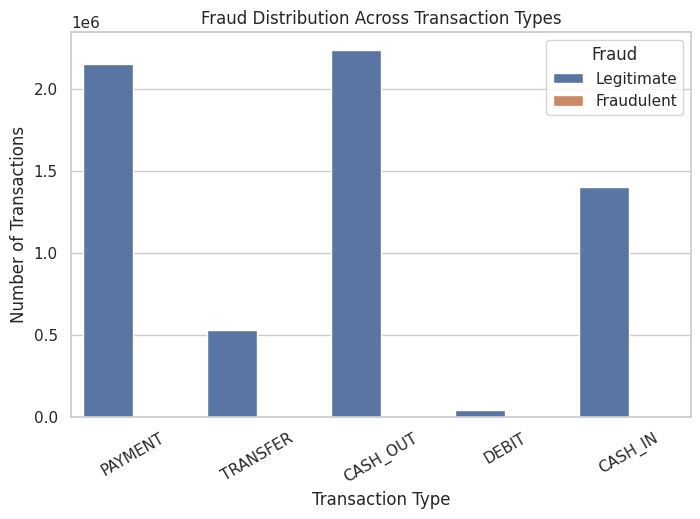

In [182]:
# Fraud distribution by transaction type
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="type",
    hue="isFraud"
)

plt.title("Fraud Distribution Across Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.legend(title="Fraud", labels=["Legitimate", "Fraudulent"])
plt.xticks(rotation=30)

plt.show()

In [183]:
# Fraud distribution by transaction type
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
) * 100

print(fraud_by_type)

isFraud            0         1
type                          
CASH_IN   100.000000  0.000000
CASH_OUT   99.816045  0.183955
DEBIT     100.000000  0.000000
PAYMENT   100.000000  0.000000
TRANSFER   99.231201  0.768799


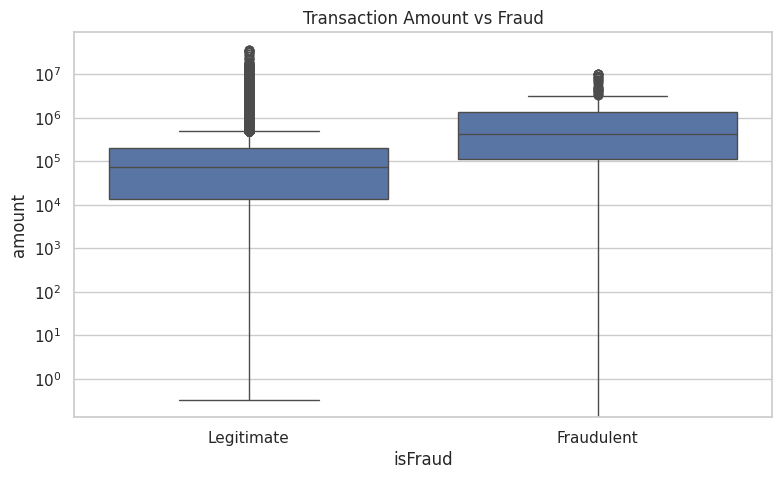

In [184]:
#Transaction amount vs fraud
sample_df = df.sample(
    n=200000,
    random_state=RANDOM_STATE
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sample_df,
    x="isFraud",
    y="amount"
)

plt.yscale("log")
plt.title("Transaction Amount vs Fraud")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

In [185]:
#Average transaction amount by class
display(
    df.groupby("isFraud")["amount"]
      .agg(["mean", "median", "min", "max"])
)

,mean,median,min,max
isFraud,,,,
0,1.781970e+05,74684.72,0.01,92445516.64
1,1.467967e+06,441423.44,0.00,10000000.00


,Fraud Percentage
type,
TRANSFER,0.768799
CASH_OUT,0.183955
CASH_IN,0.000000
DEBIT,0.000000
PAYMENT,0.000000


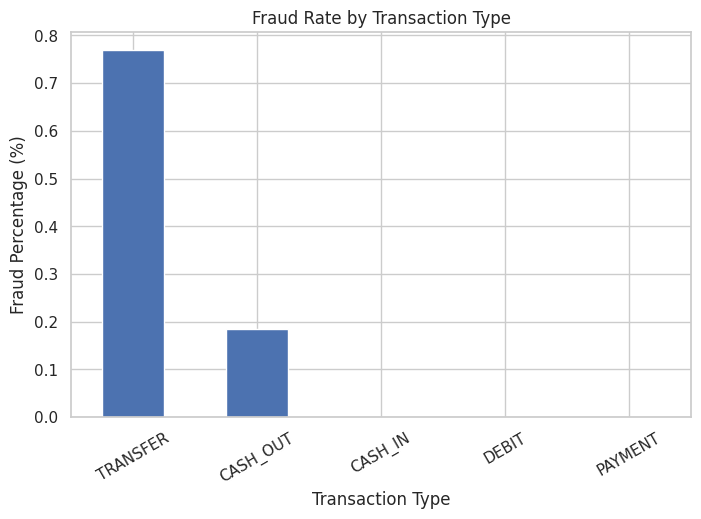

In [186]:
#Fraud percentage by transaction type
fraud_by_type = (
    df.groupby("type")["isFraud"]
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

display(fraud_by_type.to_frame("Fraud Percentage"))

fraud_by_type.plot(kind="bar", figsize=(8, 5))

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=30)

plt.show()

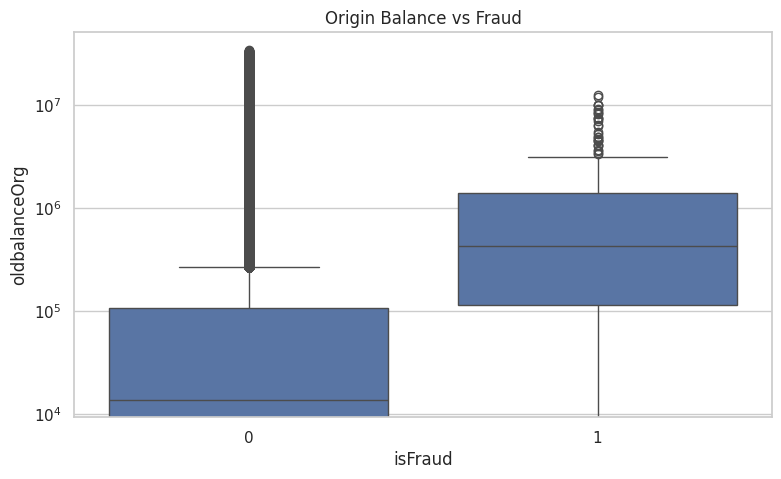

In [187]:
# Origin balance before transaction
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=sample_df,
    x="isFraud",
    y="oldbalanceOrg"
)

plt.yscale("log")
plt.title("Origin Balance vs Fraud")

plt.show()

3.3 Multivariate Analysis

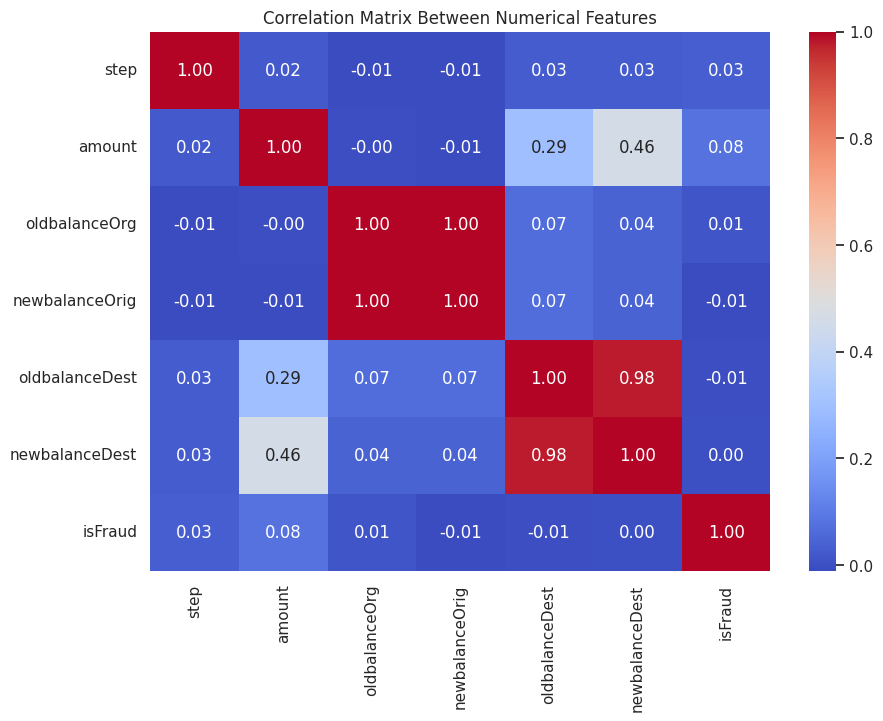

In [188]:
#Numerical correlation
plt.figure(figsize=(10, 7))

correlation = df[numerical_features + ["isFraud"]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix Between Numerical Features")
plt.show()


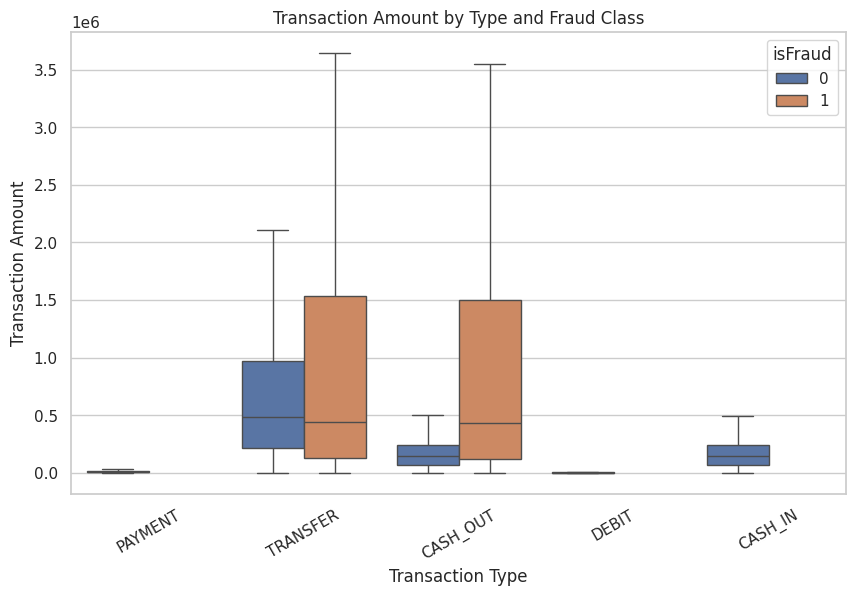

In [189]:
#Transaction type and amount by fraud
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="type",
    y="amount",
    hue="isFraud",
    showfliers=False
)

plt.title("Transaction Amount by Type and Fraud Class")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount")
plt.xticks(rotation=30)

plt.show()


isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


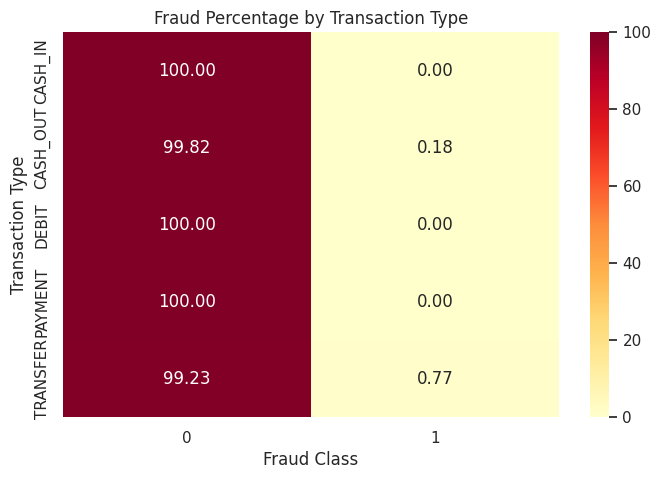

In [190]:
#Fraud distribution across transaction types
fraud_type_distribution = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
) * 100

display(fraud_type_distribution)

plt.figure(figsize=(8, 5))

sns.heatmap(
    fraud_type_distribution,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd"
)

plt.title("Fraud Percentage by Transaction Type")
plt.xlabel("Fraud Class")
plt.ylabel("Transaction Type")

plt.show()

3.4 Key EDA Insights

1. Class Imbalance: Fraudulent transactions represent a very small percentage of the dataset, making accuracy an unreliable standalone evaluation metric.
Precision, recall, and PR-AUC are more informative for evaluating fraud detection.

2. Transaction Types: Fraud was observed exclusively in TRANSFER and CASH_OUT transactions. TRANSFER had the highest fraud rate (approximately 0.77%), followed by CASH_OUT (approximately 0.18%). This makes transaction type an important feature for fraud detection.

3. Transaction Amount: Transaction amounts show different distributions across legitimate and fraudulent transactions.
Fraudulent transactions had a higher average amount (approximately 1.47 million) than legitimate transactions (approximately 178,197), suggesting that transaction amount may help identify suspicious activity.

4. Account Balances: Origin and destination balance changes provide useful information about transaction behavior and may help identify unusual account activity.

5. Feature Relationships: Strong correlations were observed between initial and new account balances, while transaction amount showed a positive relationship with destination balance updates. These relationships highlight the importance of account balance information in the detection process.

Step 4 — Data Preprocessing

4.1 Feature Selection

In [191]:
# Separate features and target
X = df[
    [
        "step",
        "type",
        "amount",
        "oldbalanceOrg",
        "oldbalanceDest"
    ]
].copy()

y = df["isFraud"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (6362620, 5)
Target shape: (6362620,)


,step,type,amount,oldbalanceOrg,oldbalanceDest
0,1,PAYMENT,9839.64,170136.0,0.0
1,1,PAYMENT,1864.28,21249.0,0.0
2,1,TRANSFER,181.00,181.0,0.0
3,1,CASH_OUT,181.00,181.0,21182.0
4,1,PAYMENT,11668.14,41554.0,0.0


4.2 Train-Test Split

In [192]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_full
)

print("Training set:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining fraud percentage:", y_train.mean() * 100)
print("Testing fraud percentage:", y_test.mean() * 100)

Training set: (4072076, 5)
Validation: (1018020, 5)
Testing set: (1272524, 5)

Training fraud percentage: 0.1290742117779727
Testing fraud percentage: 0.12911347840983745


4.3 Feature Engineering

In [211]:
import importlib
import feature_engineering

importlib.reload(feature_engineering)

from feature_engineering import create_features

4.4 Sampling strategy

In [212]:
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Original training size:", X_train.shape)
print("Sample size:", X_train_sample.shape)

print("\nClass distribution:")
print(y_train_sample.value_counts())

print("\nFraud percentage:", y_train_sample.mean() * 100)

Original training size: (4072076, 5)
Sample size: (407207, 5)

Class distribution:
isFraud
0    406681
1       526
Name: count, dtype: int64

Fraud percentage: 0.1291726321011181


4.4 Missing Values and Outliers

In [213]:
print("Training missing values:")
display(X_train_sample.isnull().sum())

print("Testing missing values:")
display(X_test.isnull().sum())

Training missing values:


step              0
type              0
amount            0
oldbalanceOrg     0
oldbalanceDest    0
dtype: int64

Testing missing values:


step              0
type              0
amount            0
oldbalanceOrg     0
oldbalanceDest    0
dtype: int64

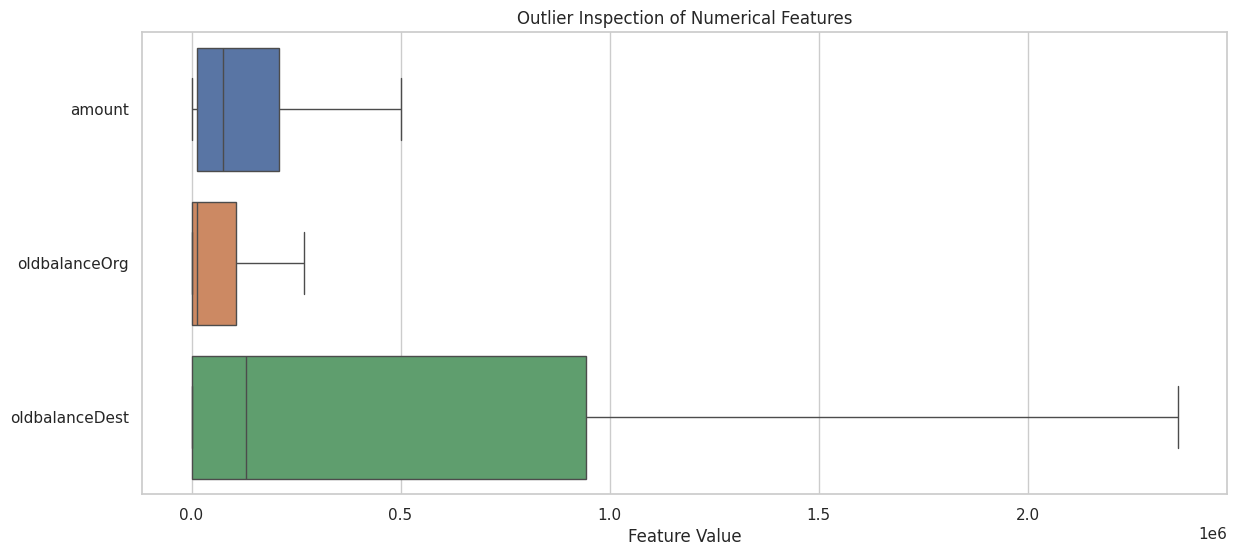

In [214]:
outlier_features = [
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
]

plt.figure(figsize=(14, 6))

sns.boxplot(data=X_train_sample[outlier_features], orient="h", showfliers=False)

plt.title("Outlier Inspection of Numerical Features")
plt.xlabel("Feature Value")

plt.show()

4.5 Encoding and Scaling

In [215]:
# Numerical features
numerical_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "hour_of_day",
    "day_number",
    "log_amount",
    "amount_to_origin_balance",
    "amount_to_destination_balance",
    "origin_balance_insufficient"
]

# Categorical features
categorical_features = ["type"]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Complete preprocessing pipeline
preprocessing_pipeline = Pipeline([
    ("feature_engineering", FunctionTransformer(
        create_features, validate=False
    )),
    ("preprocessing", preprocessor)
])

print("Preprocessing pipeline created successfully.")
display(preprocessing_pipeline)

Preprocessing pipeline created successfully.


Pipeline(steps=[('feature_engineering',
                 FunctionTransformer(func=<function create_features at 0x7fc87726a790>)),
                ('preprocessing',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'oldbalanceDest',
                                                   'hour_of_day', 'day_number',
                                                   'log_amount',
                                                   'amount_to_origin_balance',
                                                   'amount_to_destination_balance',
                                                   'origin_balance_insufficient']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['type'])]))])

4.7 Preprocessing Validation

In [216]:
print("Training features:", X_train_sample.shape)
print("Testing features:", X_test.shape)

print("\nTarget distribution in training data:")
print(y_train_sample.value_counts(normalize=True))

print("\nTarget distribution in testing data:")
print(y_test.value_counts(normalize=True))

Training features: (407207, 5)
Testing features: (1272524, 5)

Target distribution in training data:
isFraud
0    0.998708
1    0.001292
Name: proportion, dtype: float64

Target distribution in testing data:
isFraud
0    0.998709
1    0.001291
Name: proportion, dtype: float64


Step 5. Modeling

5.1 Baseline Model

In [217]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train_sample, y_train_sample)

print("Baseline model trained successfully.")
print("Predicted class:", baseline_model.predict(X_train_sample[:5]))


Baseline model trained successfully.
Predicted class: [0 0 0 0 0]


5.2 Logistic Regression

In [218]:
logistic_pipeline = Pipeline([
    ("preprocessing", preprocessing_pipeline),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="saga",
        random_state=RANDOM_STATE
    ))
])

logistic_pipeline.fit(X_train_sample, y_train_sample)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


5.3 Decision Tree

In [219]:
decision_tree_pipeline = Pipeline([
    ("preprocessing", preprocessing_pipeline),
    ("model", DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

decision_tree_pipeline.fit(X_train_sample, y_train_sample)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


5.4 Random Forest

In [220]:
random_forest_pipeline = Pipeline([
    ("preprocessing", preprocessing_pipeline),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

random_forest_pipeline.fit(X_train_sample, y_train_sample)

print("Random Forest trained successfully.")

Random Forest trained successfully.


5.5 Model Collection

In [221]:
models = {
    "Baseline": baseline_model,
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

print("Trained Models:")
for name in models:
    print("-", name)

Trained Models:
- Baseline
- Logistic Regression
- Decision Tree
- Random Forest


Compare the three models

In [222]:
models = {
    "Logistic Regression": logistic_pipeline,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = []

for name, model in models.items():

    print(f"Training {name}...")

    scores = cross_validate(
        model,
        X_train_sample,
        y_train_sample,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "PR-AUC": scores["test_pr_auc"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(cv_results)

results_df

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...


,Model,PR-AUC,Precision,Recall,F1
0,Logistic Regression,0.064619,0.007797,0.906883,0.015461
1,Decision Tree,0.950343,0.788670,0.971483,0.870260
2,Random Forest,0.982082,0.886437,0.967695,0.924810


Visualize the comparison:

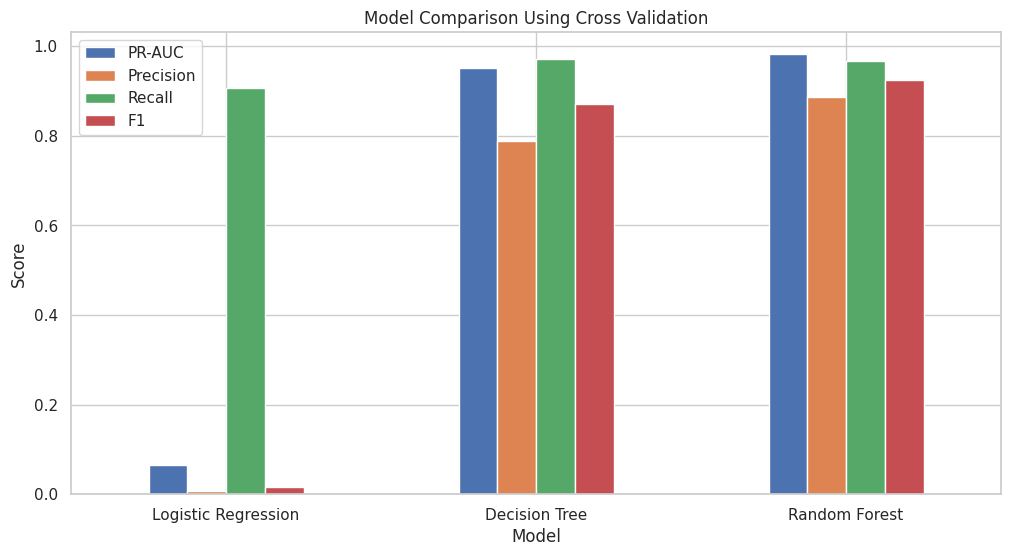

In [223]:
results_df.set_index("Model")[
    ["PR-AUC", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Comparison Using Cross Validation")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.show()

5.6 Evaluate models on validation data

In [224]:
validation_results = []
fitted_models = {}

for name, model in models.items():

    print(f"Fitting {name}...")

    model.fit(
        X_train_sample,
        y_train_sample
    )

    probabilities = model.predict_proba(X_val)[:, 1]

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    validation_results.append({
        "Model": name,
        "Validation PR-AUC": pr_auc
    })

    fitted_models[name] = model

validation_df = pd.DataFrame(
    validation_results
).sort_values(
    by="Validation PR-AUC",
    ascending=False
)

validation_df

Fitting Logistic Regression...
Fitting Decision Tree...
Fitting Random Forest...


,Model,Validation PR-AUC
2,Random Forest,0.990075
1,Decision Tree,0.856965
0,Logistic Regression,0.067016


Select the best-performing model

In [225]:
best_name = validation_df.iloc[0]["Model"]
# best_name = results_df.iloc[0]["Model"]

best_pipeline = fitted_models[best_name]

print("Best model:", best_name)

Best model: Random Forest


Step 6. Tuning & Validation

6.1 Hyperparameter Tuning options

In [226]:
param_options = {

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": ["balanced", None]
    },

    "Decision Tree": {
        "model__max_depth": [8, 12, 16, 20],
        "model__min_samples_leaf": [5, 10, 20],
        "model__class_weight": ["balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 150],
        "model__max_depth": [10, 16, 20],
        "model__min_samples_leaf": [2, 5, 10],
        "model__class_weight": ["balanced", "balanced_subsample"]
    }
}

6.2 Select Model

In [227]:
best_name = validation_df.iloc[0]["Model"]
best_pipeline = models[best_name]

print("Selected Model:", best_name)

Selected Model: Random Forest


6.3 Perform randomized search

In [228]:
search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_options[best_name],
    n_iter=5,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1
)

search.fit(
    X_train_sample,
    y_train_sample
)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessing',
                                              Pipeline(steps=[('feature_engineering',
                                                               FunctionTransformer(func=<function create_features at 0x7fc87726a790>)),
                                                              ('preprocessing',
                                                               ColumnTransformer(transformers=[('numerical',
                                                                                                Pipeline(steps=[('imputer',
                                                                                                                 SimpleImputer(strategy='median'...
                                              RandomForestClassifier(class_weight='balanced_subsample',
                                                                     max_depth=12,
                                                                     min_samples_leaf=10,
                                                                     n_jobs=-1,
                                                                     random_state=42))]),
                   n_iter=5, n_jobs=1,
                   param_distributions={'model__class_weight': ['balanced',
                                                                'balanced_subsample'],
                                        'model__max_depth': [10, 16, 20],
                                        'model__min_samples_leaf': [2, 5, 10],
                                        'model__n_estimators': [100, 150]},
                   random_state=42, scoring='average_precision', verbose=1)

6.4 Check the best parameters

In [229]:
best_model = search.best_estimator_

print("Selected Model:", best_name)
print("Best CV PR-AUC:", search.best_score_)
print("Best Parameters:")
print(search.best_params_)

Selected Model: Random Forest
Best CV PR-AUC: 0.9883352467899735
Best Parameters:
{'model__n_estimators': 150, 'model__min_samples_leaf': 2, 'model__max_depth': 20, 'model__class_weight': 'balanced'}


6.5 Validation Evaluation

In [230]:
y_val_proba = best_model.predict_proba(X_val)[:, 1]

val_pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

print("Validation PR-AUC:", val_pr_auc)

Validation PR-AUC: 0.9952598827124106


6.6 Validation Classification Metrics

In [231]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

y_val_pred = best_model.predict(X_val)

print("Validation Classification Report:")
print(classification_report(y_val, y_val_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Validation Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1016706
           1       0.99      0.93      0.96      1314

    accuracy                           1.00   1018020
   macro avg       0.99      0.96      0.98   1018020
weighted avg       1.00      1.00      1.00   1018020

Confusion Matrix:
[[1016690      16]
 [     95    1219]]


6.7 Validation Confusion Matrix

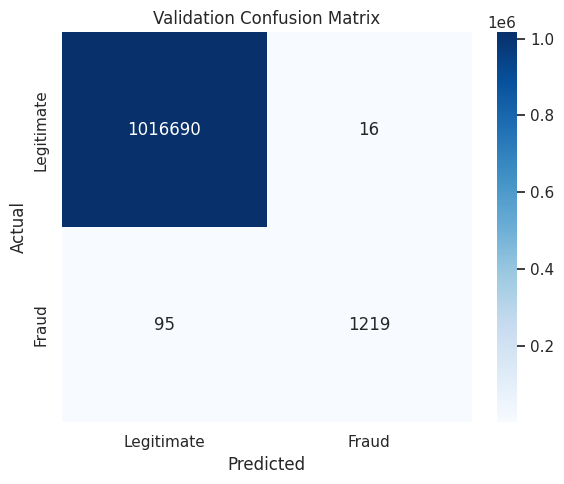

In [232]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

6.8 Validation Results Summary

In [233]:
validation_results = pd.DataFrame([{
    "Model": best_name,
    "PR-AUC": val_pr_auc,
    "Precision": precision_score(y_val, y_val_pred),
    "Recall": recall_score(y_val, y_val_pred),
    "F1-Score": f1_score(y_val, y_val_pred)
}])

display(validation_results)

,Model,PR-AUC,Precision,Recall,F1-Score
0,Random Forest,0.99526,0.987045,0.927702,0.956454


6.9 Classification Threshold Selection

In [234]:
val_probabilities = best_model.predict_proba(X_val)[:, 1]

FN_COST = 1000
FP_COST = 10

thresholds = np.linspace(0.01, 0.99, 99)

cost_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * FN_COST +
        fp * FP_COST
    )

    cost_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Total Cost": total_cost
    })

cost_df = pd.DataFrame(cost_results)

best_threshold = cost_df.loc[
    cost_df["Total Cost"].idxmin(),
    "Threshold"
]

print("Selected threshold:", best_threshold)
print("Minimum business cost:", cost_df["Total Cost"].min())

Selected threshold: 0.09999999999999999
Minimum business cost: 6050


6.10 Business Cost Visualization

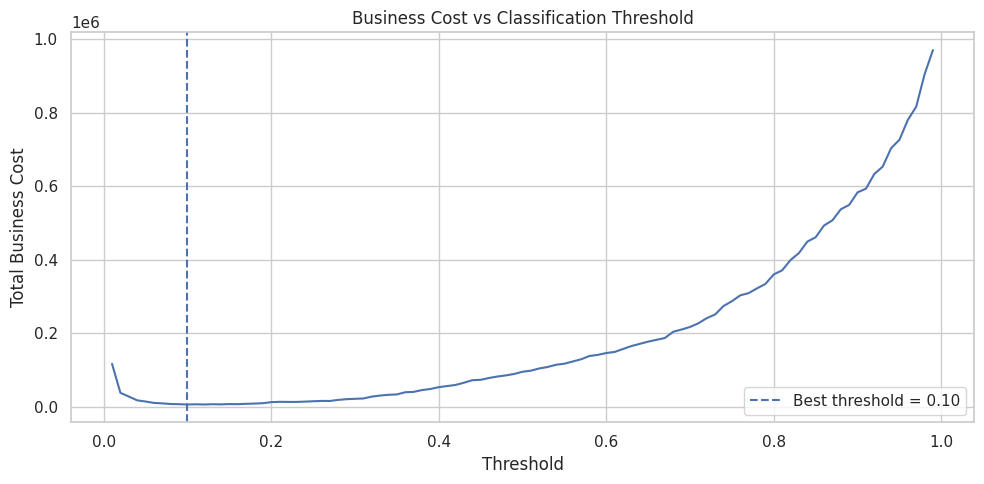

In [235]:
plt.figure(figsize=(10, 5))

plt.plot(
    cost_df["Threshold"],
    cost_df["Total Cost"]
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}"
)

plt.title("Business Cost vs Classification Threshold")
plt.xlabel("Threshold")
plt.ylabel("Total Business Cost")

plt.legend()
plt.tight_layout()
plt.show()

Step 7. Final Evaluation

7.1 Test Predictions

In [236]:
y_test_probabilities = best_model.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_probabilities >= best_threshold
).astype(int)

7.2 Final Evaluation Metrics

In [237]:
accuracy = accuracy_score(y_test, y_test_pred)

test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred,zero_division=0)

pr_auc = average_precision_score(
    y_test,
     y_test_probabilities
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_probabilities
)

print("Test Accuracy:", accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-Score:", test_f1)
print("Test PR-AUC:", pr_auc)
print("Test ROC-AUC:", test_roc_auc)

Test Accuracy: 0.9995921491461065
Test Precision: 0.7621268656716418
Test Recall: 0.9945222154595252
Test F1-Score: 0.8629522049115395
Test PR-AUC: 0.9934015436163354
Test ROC-AUC: 0.9990295518602829


7.3 Results table

In [238]:
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "PR-AUC",
        "ROC-AUC"
    ],

    "Score": [
        accuracy,
        test_precision,
        test_recall,
        test_f1,
        pr_auc,
        test_roc_auc
    ]
})

final_results

,Metric,Score
0,Accuracy,0.999592
1,Precision,0.762127
2,Recall,0.994522
3,F1-score,0.862952
4,PR-AUC,0.993402
5,ROC-AUC,0.999030


7.4 Classification Report

In [247]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00   1270881
       Fraud       0.76      0.99      0.86      1643

    accuracy                           1.00   1272524
   macro avg       0.88      1.00      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524



7.5 Confusion Matrix

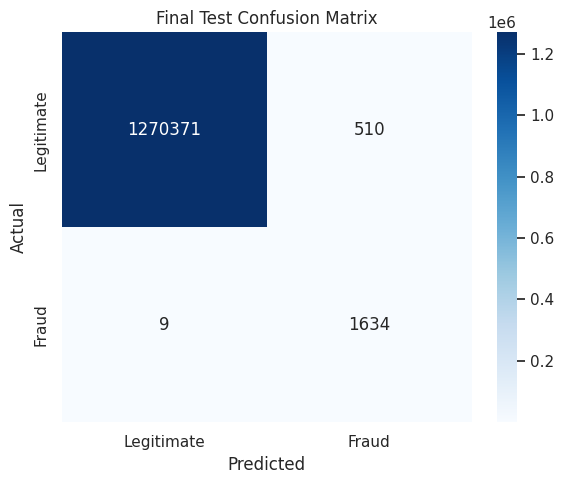

In [240]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Final Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

7.5 Precision-Recall Curve

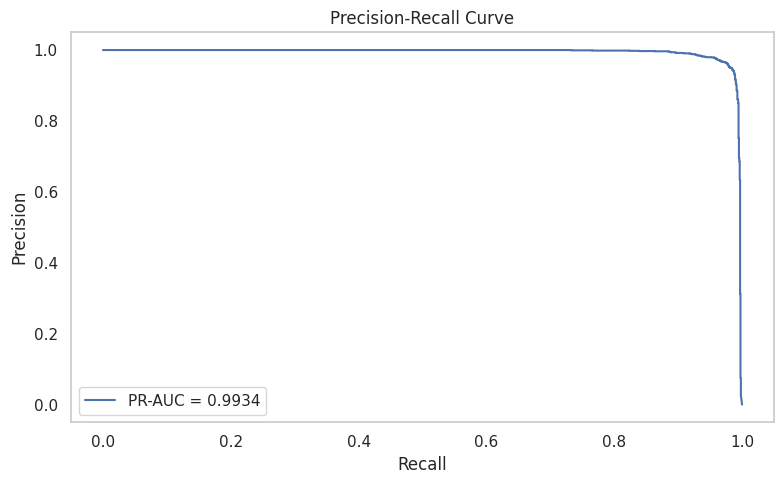

In [241]:
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_test,
        y_test_probabilities
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"PR-AUC = {pr_auc:.4f}"
)

plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

7.6 ROC Curve

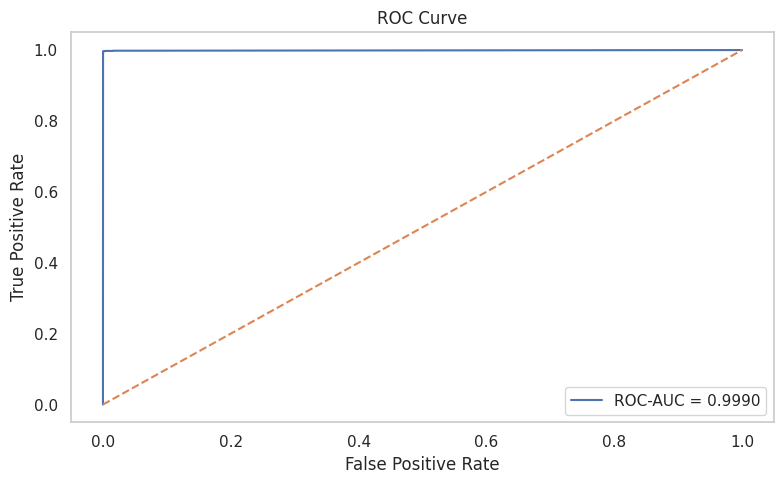

In [242]:
from sklearn.metrics import roc_curve

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_test_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {test_roc_auc:.4f}"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

7.7 Error Analysis

In [243]:
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_test_pred
error_analysis["Fraud Probability"] = y_test_probabilities

false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
]

false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
]

print("False Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

display(false_positives.head())
display(false_negatives.head())

False Positives: 510
False Negatives: 9


,step,type,amount,oldbalanceOrg,oldbalanceDest,Actual,Predicted,Fraud Probability
2216070,186,CASH_OUT,35579.05,35613.00,1188374.36,0,1,0.318097
2942340,230,TRANSFER,660284.24,829741.00,0.00,0,1,0.226624
6161907,550,TRANSFER,153320.87,390992.00,0.00,0,1,0.146552
1552729,154,CASH_OUT,254231.24,255424.69,1399151.26,0,1,0.111899
2527110,205,CASH_OUT,68560.78,68695.69,562554.63,0,1,0.297748


,step,type,amount,oldbalanceOrg,oldbalanceDest,Actual,Predicted,Fraud Probability
6281483,646,CASH_OUT,0.00,0.0,0.00,1,0,0.025395
77745,10,CASH_OUT,277970.88,0.0,0.00,1,0,0.006315
6362585,741,CASH_OUT,0.00,0.0,267522.87,1,0,0.078209
543928,21,CASH_OUT,23292.30,0.0,392364.62,1,0,0.000000
277266,15,CASH_OUT,119.00,119.0,4844060.13,1,0,0.065356


7.8 Error Analysis Summary

In [244]:
error_summary = pd.DataFrame({
    "Error Type": ["False Positives", "False Negatives"],
    "Count": [
        len(false_positives),
        len(false_negatives)
    ],
    "Business Impact": [
        "Legitimate transactions may be unnecessarily flagged.",
        "Fraudulent transactions may go undetected."
    ]
})

display(error_summary)

,Error Type,Count,Business Impact
0,False Positives,510,Legitimate transactions may be unnecessarily f...
1,False Negatives,9,Fraudulent transactions may go undetected.


7.9 Final Test Results

In [245]:
final_results = pd.DataFrame([{
    "Selected Model": best_name,
    "Threshold": best_threshold,
    "PR-AUC": pr_auc,
    "ROC-AUC": test_roc_auc,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1-Score": test_f1
}])

display(final_results)

,Selected Model,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1-Score
0,Random Forest,0.1,0.993402,0.99903,0.762127,0.994522,0.862952


8 — Business Insights

8.1 Calculate the business cost

In [246]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

false_negative_cost = fn * FN_COST

false_positive_cost = fp * FP_COST

total_business_cost = (
    false_negative_cost +
    false_positive_cost
)

print("Missed fraud cost:", false_negative_cost)

print("False alarm cost:", false_positive_cost)

print("Total business cost:", total_business_cost)

Missed fraud cost: 9000
False alarm cost: 5100
Total business cost: 14100


8.2 Business Interpretation

The Random Forest model achieved a test PR-AUC of '0.9934' and ROC-AUC of '0.9990', indicating excellent performance in distinguishing fraudulent transactions from legitimate ones on the test dataset.

Using the selected classification threshold of '0.10', the model achieved a fraud recall of '99.45%', meaning that it detected approximately 99.45% of fraudulent transactions. Its fraud precision was '76.21%', meaning that approximately 76% of the transactions flagged as fraudulent were actually fraudulent.

The model successfully detected '1,634 fraudulent transactions' and missed only '9 fraudulent transactions'. It also generated '510 false positives', meaning that some legitimate transactions were incorrectly flagged for investigation.

The model achieved an F1-score of '0.8630' and an accuracy of '99.96%'. However, because the dataset is highly imbalanced, precision, recall, and PR-AUC provide more meaningful insights into fraud detection performance than accuracy alone.

Under the assumed business costs, the total estimated cost on the test set was '14,100'. This consisted of:

- Missed fraud cost: 9,000 (9 false negatives × 1,000).
- False alarm cost: 5,100 (510 false positives × 10).

These results indicate that the model successfully detects almost all fraudulent transactions while maintaining a relatively limited number of false alarms.

Overall, the Random Forest model provides a strong balance between fraud detection and investigation workload, making it a promising approach for supporting mobile wallet fraud detection.

8.3 Business Recommendations

Based on the EDA findings and model evaluation, the company should consider the following actions:

1. Focus on High-Risk Transactions: Apply additional fraud screening to TRANSFER and CASH_OUT transactions, as these were the transaction types associated with fraud in the PaySim dataset.

2. Use Transaction Amounts and Initial Balances as Risk Signals: Consider transaction amount, origin balance, and destination balance when calculating transaction risk. High-value transactions and unusual relationships between transaction amounts and available balances should receive additional attention rather than being automatically classified as fraudulent.

3. Implement Risk-Based Transaction Screening: Use the predicted fraud probability to prioritize transactions. Transactions with probabilities above the selected threshold of 0.10 can be flagged for additional screening.

4. Introduce Manual Review: Route suspicious transactions to a fraud investigation team before taking action. This helps reduce the impact of false positives on legitimate customers.

5. Reduce False Positives: Investigate the 510 false-positive cases to identify patterns that distinguish legitimate transactions from fraudulent ones. This could help reduce unnecessary investigations and improve the customer experience.

6. Investigate Missed Fraud Cases: Analyze the 9 fraudulent transactions that the model failed to detect. Understanding their characteristics may reveal additional patterns that could improve future fraud detection.

7. Monitor Model Performance: Regularly evaluate precision, recall, F1-score, PR-AUC, and false-positive rates to ensure that the model continues to perform effectively as transaction patterns change.

8. Optimize Business Costs: Reassess the assumed costs of missed fraud and false alarms using actual company data. The classification threshold should be adjusted according to the organization's financial priorities and investigation capacity.

8.4 Model Limitations

Despite its promising results, the model has several limitations:

1. Synthetic Dataset: PaySim is a simulated dataset, so its transaction patterns may not fully represent real-world mobile wallet fraud behavior. High performance on this dataset does not guarantee similar results in a production environment.

2. Class Imbalance: Fraudulent transactions represent a very small proportion of the dataset, making reliable fraud detection challenging. Although the model achieved high recall and PR-AUC, class imbalance remains an important consideration.

3. False Positives: The model generated 510 false positives on the test set. These legitimate transactions could require unnecessary investigation, increasing operational workload and potentially inconveniencing customers.

4. Missed Fraud: The model failed to detect 9 fraudulent transactions. Although this represents a small proportion of the fraudulent transactions in the test set, undetected fraud can still result in financial losses.

5. Assumed Business Costs: The cost values used for threshold selection are hypothetical and may not reflect actual financial losses or operational expenses. Therefore, the estimated business cost should be treated as an illustrative measure rather than a real financial prediction.

6. Limited Fraud Patterns: Fraud was observed only in TRANSFER and CASH_OUT transactions in this dataset. Real-world fraud may occur across additional transaction types and may involve more complex patterns.

7. Generalization: The Random Forest model achieved excellent results on the PaySim test set, but performance on real transaction data may differ because of changes in customer behavior, fraud strategies, and transaction patterns.

8. Feature Availability: The model uses information available before transaction completion. However, its effectiveness depends on the accuracy and availability of these input features in a real mobile wallet system.

8.5 Final Conclusion

This project developed a machine learning approach for detecting fraudulent mobile wallet transactions using the PaySim dataset. Several machine learning algorithms were evaluated, and Random Forest was selected and optimized through hyperparameter tuning.

The final model used a classification threshold of 0.10 and achieved a test PR-AUC of 0.9934, ROC-AUC of 0.9990, precision of 76.21%, and recall of 99.45%.

It successfully detected 1,634 out of 1,643 fraudulent transactions, missing only 9 fraudulent transactions while generating 510 false positives. Under the assumed business costs, the estimated total cost on the test set was 14,100.

These results demonstrate the potential of machine learning, particularly Random Forest, for identifying fraudulent mobile wallet transactions while maintaining a high fraud detection rate.

However, further testing with real transaction data, additional fraud-related features, and realistic business cost estimates would be necessary before deploying the model in a production environment.

Step 9 — Save the Final Model

9.1 Save the Final Model

In [248]:
best_model = search.best_estimator_

print("Selected Model:", best_name)
print("Best CV PR-AUC:", search.best_score_)
print("Best Parameters:")
print(search.best_params_)

Selected Model: Random Forest
Best CV PR-AUC: 0.9883352467899735
Best Parameters:
{'model__n_estimators': 150, 'model__min_samples_leaf': 2, 'model__max_depth': 20, 'model__class_weight': 'balanced'}


9.2 Update the feature engineering reference

In [249]:
from feature_engineering import create_features

best_model.set_params(
    preprocessing__feature_engineering__func=create_features
)

Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('feature_engineering',
                                  FunctionTransformer(func=<function create_features at 0x7fc87726a790>)),
                                 ('preprocessing',
                                  ColumnTransformer(transformers=[('numerical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='median')),
                                                                                   ('scaler',
                                                                                    RobustScaler())]),
                                                                   ['step',
                                                                    'amount',
                                                                    'oldbalanceOrg',
                                                                    'oldbalanceDest',
                                                                    'hour_of...
                                                                    'amount_to_destination_balance',
                                                                    'origin_balance_insufficient']),
                                                                  ('categorical',
                                                                   Pipeline(steps=[('imputer',
                                                                                    SimpleImputer(strategy='most_frequent')),
                                                                                   ('encoder',
                                                                                    OneHotEncoder(handle_unknown='ignore'))]),
                                                                   ['type'])]))])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=20,
                                        min_samples_leaf=2, n_estimators=150,
                                        n_jobs=-1, random_state=42))])

9.3 Refit the final model

In [250]:
best_model.fit(
    X_train_sample,
    y_train_sample
)

print("Final model trained successfully!")

Final model trained successfully!


9.3 Save the model

In [251]:
import joblib

model_bundle = {
    "model": best_model,
    "threshold": float(best_threshold)
}

joblib.dump(
    model_bundle,
    "fraud_detection_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


9.4 Verify the file

In [252]:
import os

print(
    "File exists:",
    os.path.exists("fraud_detection_model.joblib")
)

print(
    "File size:",
    round(
        os.path.getsize("fraud_detection_model.joblib") / (1024 * 1024),
        2
    ),
    "MB"
)

File exists: True
File size: 3.15 MB


9.5 Prepare a demonstration CSV

In [253]:
demo_data = X_test.copy()

demo_data["isFraud"] = y_test

demo_sample = demo_data.sample(
    n=min(5000, len(demo_data)),
    random_state=RANDOM_STATE
)

demo_sample.to_csv(
    "demo_transactions.csv",
    index=False
)

print("Demo CSV created successfully!")

display(demo_sample.head())

Demo CSV created successfully!


,step,type,amount,oldbalanceOrg,oldbalanceDest,isFraud
1220251,133,CASH_OUT,135627.66,0.00,196307.15,0
5806139,401,TRANSFER,104716.54,0.00,1855955.66,0
1436860,140,PAYMENT,15229.00,44600.60,0.00,0
946770,44,PAYMENT,17685.95,1045.00,0.00,0
3753327,279,PAYMENT,2672.66,71028.51,0.00,0
